* plot $a_{Q^*}$ as function of $\sqrt{\Delta P}$ using both methods, why the analytical method doesn't give us a straight line $a_{Q^*}\propto \sqrt{\Delta P}$ $\checkmark$
* check $P(T, \mu)$ full numerical integral and Summerfeld approximation $\checkmark$
* check difference between $P(T ,\mu)$, and $n(T, \mu)$ $\checkmark$
* does other form of $w(T)$ work
* the analytic $z(t) = (z_0^{1/2} - Ct)^2$ solution correct or not?

# Plot $a_{Q^*}$ as function of $\sqrt{\Delta P}$

In [3]:
import numpy as np
import time
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, Get_Two_as_pres, _find_muB_muK_star

plt.rcParams["figure.dpi"] = 150
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

In [5]:
PNM_n(3*n0, 10)/1e8

6.115366319032183

In [21]:
DelP_list = np.linspace(1e+7, 6e+8, 100)
aQstar_list_num = [] # numerical
aQstar_list_ana = [] # analytical
for i in tqdm(range(100)):
    aQtmp_num, _ = Get_Two_as_pres(
        T = 10,
        P_crit = 6e8,
        DelP = DelP_list[i],
        m_s = 0,
        param = para.paraQMCRMF3,
        NM_type = "PNM",
        aQmax = True
    )
    aQtmp_ana, _ = Get_Two_as_pres(
        T = 10,
        P_crit = 6e8,
        DelP = DelP_list[i],
        m_s = 0,
        param = para.paraQMCRMF3,
        NM_type = "PNM",
        aQmax = False
    )
    aQstar_list_num.append(aQtmp_num)
    aQstar_list_ana.append(aQtmp_ana)


00%|█████████████████████████████████████████| 100/100 [21:16<00:00, 12.76s/it]

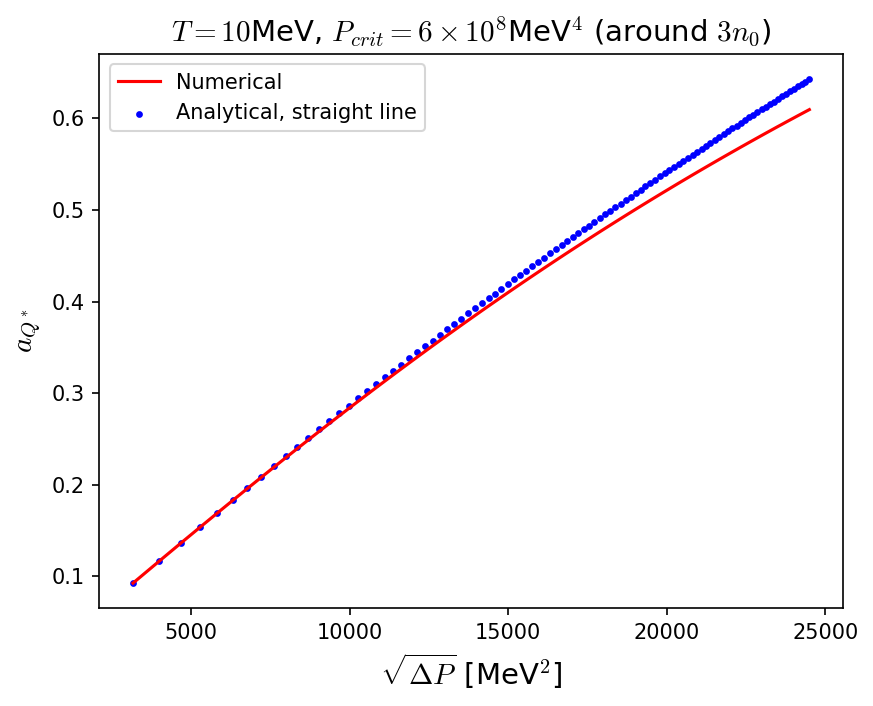

In [25]:
plt.rcParams["figure.dpi"] = 150
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

plt.plot(np.sqrt(DelP_list), aQstar_list_num, 'r', label='Numerical')
plt.scatter(np.sqrt(DelP_list), aQstar_list_ana, c='b', s=5, label='Analytical, straight line')
plt.xlabel(r'$\sqrt{\Delta P}$ [MeV$^2$]', fontsize=14)
plt.ylabel(r'$a_{Q^*}$', fontsize=14)
plt.title(r'$T = 10$MeV, $P_{crit} = 6\times 10^8$MeV$^4$ (around $3n_0$)', fontsize=14)
plt.legend()

The analytical expression isn't strictly a straight line. This is because as $\Delta P$ increase, the value for $n_B^Q$ also increases. The suseptability $\chi_K^Q = \partial^2P_{SQM}/\partial\mu_K^2$ is a bit hard to see whether it increases or not, but it's decreasing, because the instant radius of the isobar is increasing. See the formula:
$$
a_{Q^*}^{\mathrm{max}} \approx \sqrt{ \frac{2 (\mu_B^N - \mu_B^Q)}{n_B^Q}\left. \frac{\partial^2 P_{SQM}}{\partial\mu_K^2}\right|_{Q}}.
$$

* in the paper we can mention $n_B^Q(\Delta P)$...

# Plot full $P(\mu, T)$ integral and Summerfeld expalsion 

In [4]:
def _log1p_exp_neg(a):
    # stable log(1 + exp(-a))
    if a > 50.0:
        return np.exp(-a)
    if a < -50.0:
        return -a
    return np.log1p(np.exp(-a))

def _smoothstep01(x):
    # C^1 smooth blend on [0,1]
    x = 0.0 if x < 0.0 else (1.0 if x > 1.0 else x)
    return x*x*(3.0 - 2.0*x)

def _Tswitch_free_pressure(mu, m, rtol=1e-6, band=1.25):
    """
    Adaptive switch band (T_lo, T_hi) between T=0 formula and finite-T integral
    for a free fermion pressure. If mu <= m, returns (0.0, 0.0) → use integral only.
    """
    mu = float(mu); m = float(m)
    if mu <= m:
        return (0.0, 0.0)

    # exact T=0 pressure P0 and Sommerfeld prefactor f(μ,m)
    if m == 0.0:
        P0 = mu**4 / (12.0*np.pi**2)
        f  = (mu*mu) / (np.pi**2)
    else:
        kF = _kF(mu, m)
        P0 = ((2.0/3.0 * kF**3 - m*m * kF) * mu
              + m**4 * np.log((kF + mu) / max(m, 1e-300))) / (8.0*np.pi**2)
        f  = (mu * kF) / (np.pi**2)

    if P0 <= 0.0 or f <= 0.0:
        return (0.0, 0.0)

    T_star = np.sqrt((6.0 * rtol * P0) / (np.pi**2 * f))
    return (T_star / band, T_star * band)

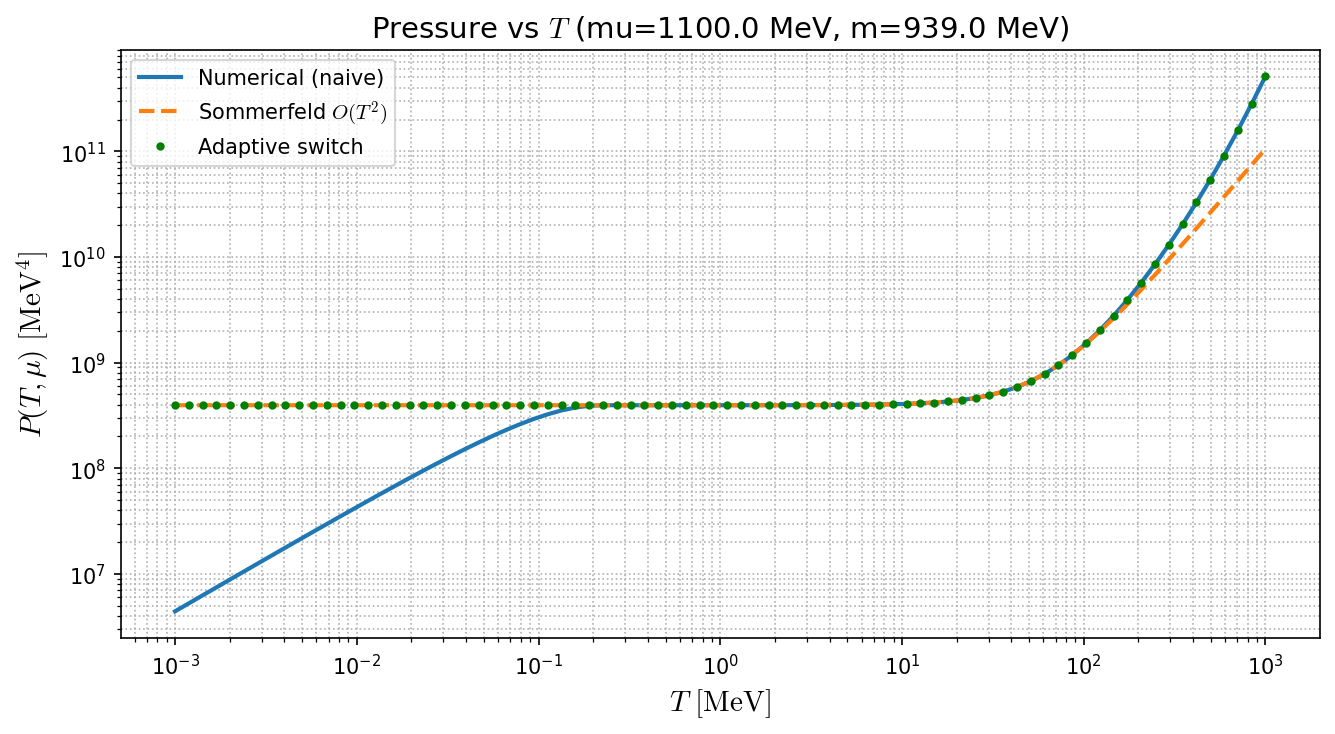

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from RMFsolver.phase_velocity import P_f

# ----------------------------
# basic helpers
# ----------------------------

def kF(mu, m):
    return np.sqrt(max(mu*mu - m*m, 0.0))

def P0_free(mu, m):
    if mu <= m:
        return 0.0
    if m == 0.0:
        return mu**4 / (12.0 * np.pi**2)
    kF_val = kF(mu, m)
    return (
        (2.0 * kF_val**3 - 3.0 * m*m * kF_val) * mu
        + 3.0 * m**4 * np.log((kF_val + mu) / max(m, 1e-300))
    ) / (24.0 * np.pi**2)

def fP_sommerfeld(mu, m):
    if mu <= m:
        return 0.0
    if m == 0.0:
        return (mu * mu) / (np.pi**2)
    return (mu * kF(mu, m)) / (np.pi**2)

def P_sommerfeld(mu, m, T):
    return P0_free(mu, m) + (np.pi**2 / 6.0) * (T*T) * fP_sommerfeld(mu, m)

# ---------- naive log helper (to SHOW the problem) ----------
def log1p_exp_neg_naive(a):
    a = float(np.clip(a, -700.0, 700.0))
    return np.log1p(np.exp(-a))

# ---------- stable log helper (our fix) ----------
def P_int_naive(mu, m, T, upB=np.inf):
    if T <= 0.0:
        return P0_free(mu, m)

    def integrand(k):
        Ek = np.sqrt(k*k + m*m)
        a = (Ek - mu) / T
        b = (Ek + mu) / T
        return T * (log1p_exp_neg_naive(a) + log1p_exp_neg_naive(b)) * (k*k)

    ub = float(upB) if np.isfinite(upB) else np.inf
    Pint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    return Pint / (np.pi**2)

def P_int_stable(mu, m, T, upB=4000.0):
    if T <= 0.0:
        return P0_free(mu, m)

    def integrand(k):
        Ek = np.sqrt(k*k + m*m)
        a = (Ek - mu) / T
        b = (Ek + mu) / T
        return T * (_log1p_exp_neg(a) + _log1p_exp_neg(b)) * (k*k)

    ub = float(upB) if np.isfinite(upB) else np.inf
    Pint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
    return Pint / (np.pi**2)


# ----------------------------
# choose fermion and T grid
# ----------------------------

m = 939.0
mu = 1100.0
T_vals = np.logspace(-3, np.log10(1000), 80)

# ----------------------------
# compute curves
# ----------------------------

P_num_naive = np.array([P_int_naive(mu, m, T) for T in T_vals])
P_somm_vals = np.array([P_sommerfeld(mu, m, T) for T in T_vals])
P_adapt     = np.array([P_f(mu, m, T) for T in T_vals])

# ----------------------------
# plot
# ----------------------------

plt.figure(figsize=(9,5))
plt.loglog(T_vals, P_num_naive, label="Numerical (naive)", lw=2)
plt.loglog(T_vals, P_somm_vals, "--", label="Sommerfeld $O(T^2)$", lw=2)
plt.loglog(T_vals, P_adapt, "g.", label="Adaptive switch", lw=2)

plt.xlabel(r"$T\ \mathrm{[MeV]}$", fontsize=14)
plt.ylabel(r"$P(T,\mu)\ \mathrm{[MeV}^4\mathrm{]}$", fontsize=14)
plt.title(rf"Pressure vs $T$ (mu={mu:.1f} MeV, m={m:.1f} MeV)", fontsize=14)
plt.grid(True, which="both", ls=":")
plt.legend()
plt.tight_layout()
plt.show()

#### In RMF setting, the following simple fix won't work
$$
\ln(1 + e^{-(E^*_k - \mu_{\mathrm{eff}})/T})\simeq e^{-(E^*_k - \mu_{\mathrm{eff}})/T}\;,\quad \text{for smaller } T
$$

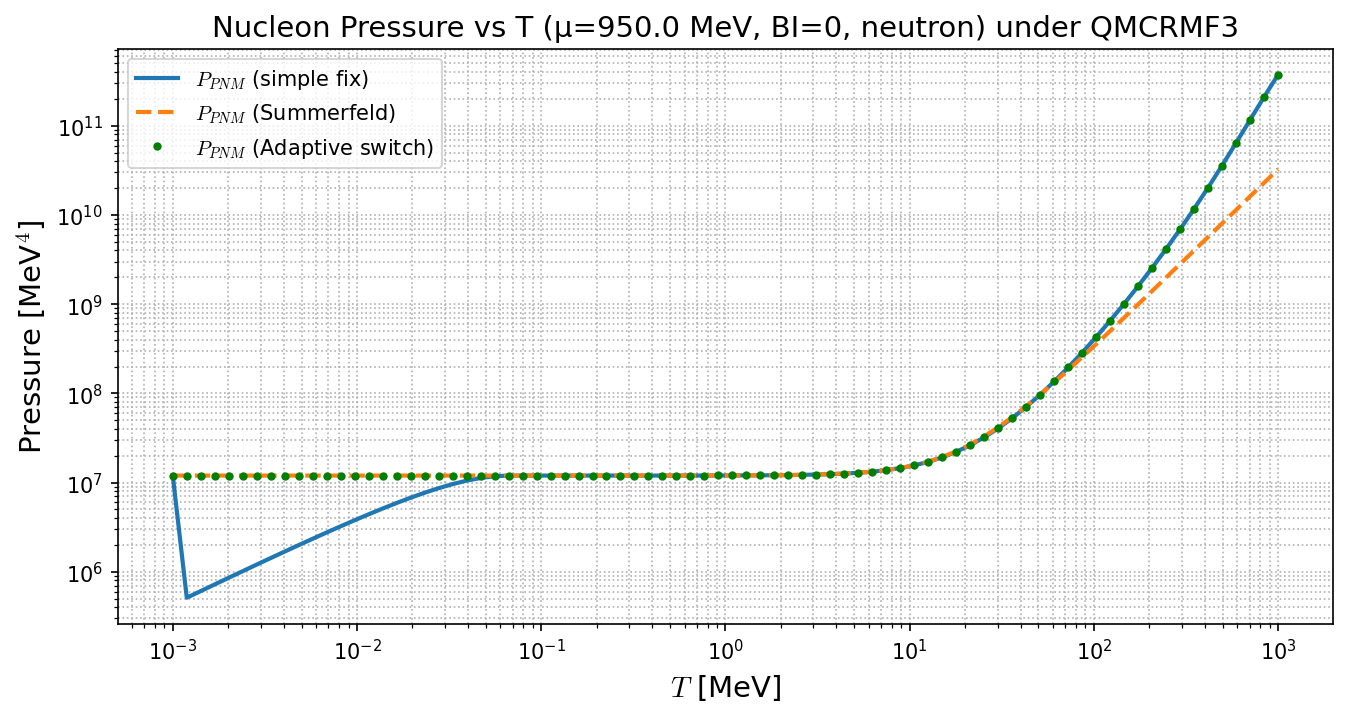

In [17]:
# --- Configuration ---
BI_choice     = 0        # baryon index: 0 for proton, 1 for neutron
mu_choice     = 950.0    # typical μ_B (MeV)
sigma_choice  = 30.0     # mean-field σ (MeV)
w0_choice     = 20.0     # mean-field ω₀ (MeV)
r03_choice    = -3.0     # mean-field ρ₀³ (MeV)
upB_choice    = float('inf')

# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.Solver_original import nucleon_pressure as nucleon_pressure_old
from RMFsolver.Solver_original import nucleon_pressure_fixed as nucleon_pressure_old_fixed
from RMFsolver.Solver_original import nucleon_pressure_sommerfeld
from RMFsolver.Solver_original import _set_couplings as _set_couplings_old
from RMFsolver.Solver import nucleon_pressure
from RMFsolver.Solver import _set_couplings 

_set_couplings_old(para.paraQMCRMF3)
_set_couplings(para.paraQMCRMF3)

# new smooth version should already be defined as nucleon_pressure_test in this notebook

# --- Temperature grid ---
TT = np.logspace(-3, np.log10(1000), 80)

# --- Evaluate both versions ---
#P_old = np.empty_like(TT)
P_old_fixed = np.empty_like(TT)
P_som = np.empty_like(TT)
P_new = np.empty_like(TT)

for i, T in enumerate(TT):
    #P_old[i] = nucleon_pressure_old(T, mu_choice, sigma_choice, w0_choice, r03_choice, BI_choice)
    P_old_fixed[i] = nucleon_pressure_old_fixed(T, mu_choice, sigma_choice, w0_choice, r03_choice, BI_choice)
    P_som[i] = nucleon_pressure_sommerfeld(T, mu_choice, sigma_choice, w0_choice, r03_choice, BI_choice)
    P_new[i] = nucleon_pressure(T, mu_choice, sigma_choice, w0_choice, r03_choice, BI_choice)

# --- Plot results ---
plt.figure(figsize=(9,5))
#plt.plot(TT, P_old, label="nucleon_pressure (old)", lw=2)
plt.plot(TT, P_old_fixed, label=r"$P_{PNM}$ (simple fix)", lw=2)
plt.plot(TT, P_som, '--', label=r"$P_{PNM}$ (Summerfeld)", lw=2)
plt.plot(TT, P_new,  "g.", label=r"$P_{PNM}$ (Adaptive switch)", lw=2,)
plt.xlabel(r"$T$ [MeV]", fontsize=14)
plt.ylabel(r"Pressure [MeV$^4$]", fontsize=14)
plt.title(f"Nucleon Pressure vs T (μ={mu_choice} MeV, BI={BI_choice}, neutron) under QMCRMF3", fontsize=14)
plt.grid(True, which="both", ls=":")
plt.legend()
plt.tight_layout()
plt.xscale('log')
plt.yscale('log')
plt.show()


# Using another form of $P(\mu, T)$
using integrate by parts, the pressure for a single fermion species:
$$
P = \frac{T}{\pi^2}\int_0^\infty k^2dk\,\bigg[\ln\bigg(1 + e^{-\frac{E_k - \mu}{T}}\bigg) + \ln\bigg(1 + e^{-\frac{E_k + \mu}{T}}\bigg) \bigg]
$$
can be mathematically expressed equivalently by
$$
P = \frac{1}{\pi^2}\int_0^\infty k^3dk\,\frac{1}{3}\frac{dE_k}{dk}\bigg[ \frac{1}{1 + e^{(E_k - \mu)/T}} + \frac{1}{1 + e^{(E_k + \mu)/T}} \bigg]
$$

In [23]:
def P_f_int_by_parts(mu, m, Tem, upB=np.inf):
    '''
    Computes pressure for a single fermion species

    Parameters:
    - mu   : fermion chemical potential
    - m    : fermion mass
    - Tem  : temperature
    - upB  : upper limit for infinite integral, default=5000

    Returns:
    - pressure of this fermion species
    '''

    if Tem > 1e-3:
        def integrand(k):
            Ek = np.sqrt(k**2 + m**2)
            fd = 1/(1 + np.exp(np.clip((Ek - mu)/Tem, -700, 700)))
            fd_bar = 1/(1 + np.exp(np.clip((Ek + mu)/Tem, -700, 700)))
            return (fd + fd_bar) * k**4 / (3 * Ek)

        integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)

        return float( integral / (np.pi**2) )

    else:
        if m < 1e-3:
            return float( mu**4 / (12 * np.pi**2) )
        else:
            k_F = np.sqrt(np.maximum(mu**2 - m**2, 0.0))
            return float( ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2) )

time ibp / time adapt =  7.382228768934561


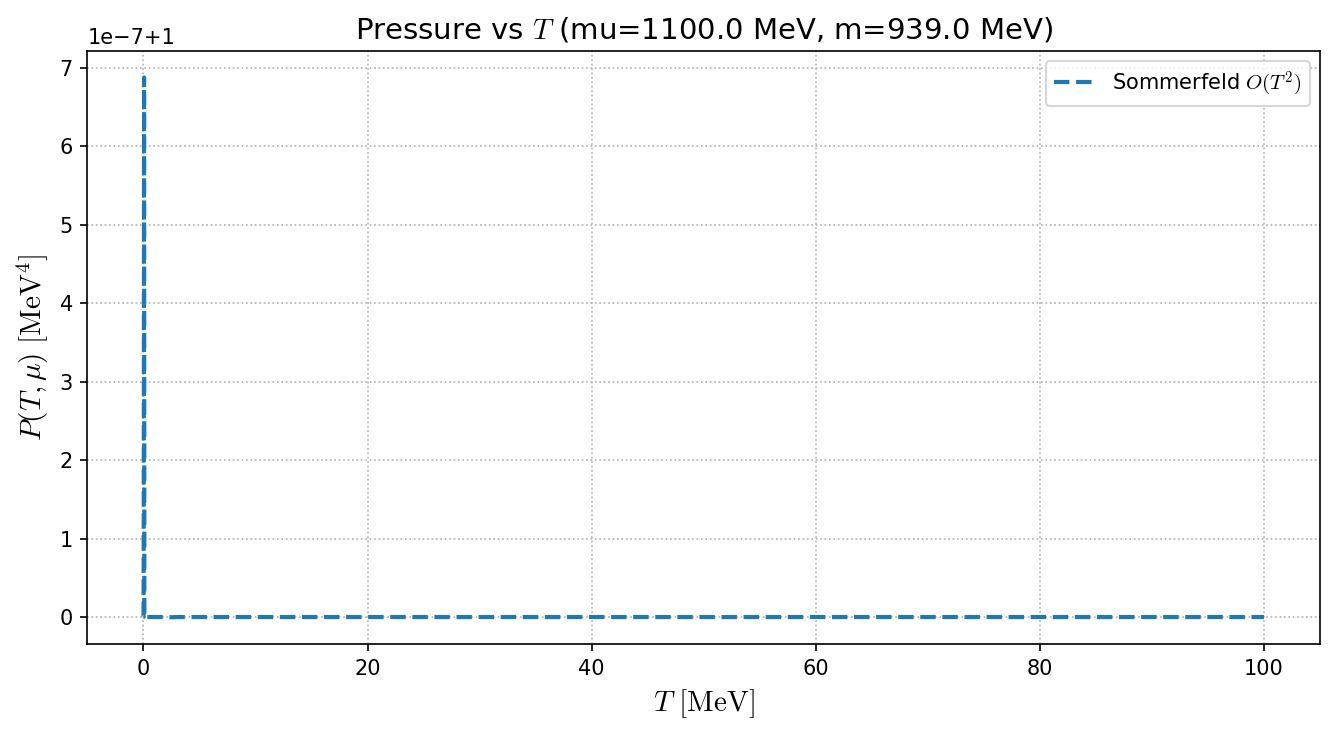

In [31]:
m = 939.0
mu = 1100.0
T_vals = np.logspace(-5, np.log10(100), 80)

# ----------------------------
# compute curves
# ----------------------------

start = time.time()
P_int_by_parts = np.array([P_f_int_by_parts(mu, m, T) for T in T_vals])
mid = time.time()
P_adapt     = np.array([P_f(mu, m, T) for T in T_vals])
end = time.time()

t1 = mid - start
t2 = end - mid
print("time ibp / time adapt = ", t1/t2)

P_ratio = P_int_by_parts/P_adapt

# ----------------------------
# plot
# ----------------------------

plt.figure(figsize=(9,5))
#plt.loglog(T_vals, P_int_by_parts, label="Integral by parts", lw=2)
plt.plot(T_vals, P_ratio, "--", label="Sommerfeld $O(T^2)$", lw=2)
#plt.loglog(T_vals, P_adapt, "g.", label="Adaptive switch", lw=2)

plt.xlabel(r"$T\ \mathrm{[MeV]}$", fontsize=14)
plt.ylabel(r"$P(T,\mu)\ \mathrm{[MeV}^4\mathrm{]}$", fontsize=14)
plt.title(rf"Pressure vs $T$ (mu={mu:.1f} MeV, m={m:.1f} MeV)", fontsize=14)
plt.grid(True, which="both", ls=":")
plt.legend()
plt.tight_layout()
plt.show()

def P_f_int_by_parts(mu, m, Tem, upB=np.inf):
    '''
    Computes pressure for a single fermion species

    Parameters:
    - mu   : fermion chemical potential
    - m    : fermion mass
    - Tem  : temperature
    - upB  : upper limit for infinite integral, default=5000

    Returns:
    - pressure of this fermion species
    '''

    if Tem > 1e-3:
        def integrand(k):
            Ek = np.sqrt(k**2 + m**2)
            fd = 1/(1 + np.exp(np.clip((Ek - mu)/Tem, -700, 700)))
            fd_bar = 1/(1 + np.exp(np.clip((Ek + mu)/Tem, -700, 700)))
            return (fd + fd_bar) * k**4 / (3 * Ek)

        integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)

        return float( integral / (np.pi**2) )

    else:
        if m < 1e-3:
            return float( mu**4 / (12 * np.pi**2) )
        else:
            k_F = np.sqrt(np.maximum(mu**2 - m**2, 0.0))
            return float( ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2) )

* calculate and get a number for $C$
* $z(t) = (z^{\prime 1/2} - C(t - t^\prime))^2$, choose a $t^\prime$, compare numerical solution and analytical from window $(t^\prime\sim t_1)$